<a href="https://colab.research.google.com/github/Rahul-Garg2006/DNN_Project/blob/main/defect_training_v2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Improved training run (one pass) — train and compare the 3 models

**What is different from your first training notebook.** This is the same workflow and the same three models, with three changes that target the weaknesses the first run showed (good prints confused with under-extrusion / stringing, and a gap on the Kaggle oblique/silver images):

1. **Higher image resolution (256 instead of 224)** — keeps the fine texture that tells stringing, under-extrusion and good apart.
2. **Stronger augmentation** (rotation, perspective, stronger colour, occasional grayscale) — for the oblique-angle and silver-bed images.
3. **Focal loss instead of plain weighted loss** — focuses training on the hard, confused cases.

**Your first run is not touched.** This notebook saves to `defect_project/models_improved/` and `defect_project/results_improved/`, so you can compare the two runs.

**How to use it:** Runtime -> Change runtime type -> **T4 GPU**. Run top to bottom. Do the quick `SMOKE = True` check first, then set it to `False` for the real run. If Colab runs out of memory at 256, lower `BATCH` to 16.

## Step 1: Set up (library, Drive, GPU)

In [ ]:
%pip install -q timm
import os, time, json, random, zipfile, copy
from pathlib import Path

try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Not running in Colab, skipping the Drive mount.')

import numpy as np, pandas as pd
import torch, torch.nn as nn, torchvision, timm
import torchvision.transforms as T
from PIL import Image, ImageOps
from sklearn.metrics import f1_score, accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt

DRIVE = Path(os.environ.get('DEFECT_DRIVE', '/content/drive/MyDrive/defect_project'))
LOCAL = Path(os.environ.get('DEFECT_LOCAL', '/content/data'))
MODELS_DIR  = DRIVE / 'models_improved'     # NEW folders: the first run is left untouched
RESULTS_DIR = DRIVE / 'results_improved'
for p in (MODELS_DIR, RESULTS_DIR):
    p.mkdir(parents=True, exist_ok=True)

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', device, '-', torch.cuda.get_device_name(0) if device == 'cuda' else 'NO GPU')
if device == 'cpu':
    print('WARNING: no GPU found. Runtime > Change runtime type > T4 GPU, then run this cell again.')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Device: cuda - Tesla T4


## Step 2: Settings  (YOU MAY EDIT THIS)
- `SMOKE = True` runs a tiny, fast version to check nothing is broken. **Set it to `False` for the real run.**
- The three changes live here: `IMG = 256`, the stronger augmentation (Step 3), and `USE_FOCAL = True`.
- If Colab says it ran out of GPU memory, lower `BATCH` to 16.

In [ ]:
SMOKE = False       # <- first run: True (quick check). Real run: False
SEED = 42
IMG = 256             # higher than before (was 224) to keep fine defect texture
BATCH = 24            # lower than before (was 32) because 256 uses more memory; drop to 16 if out-of-memory
WORKERS = 2
PRETRAINED = os.environ.get('DEFECT_PRETRAINED', '1') == '1'
PATIENCE = 4
USE_FOCAL = True      # focal loss focuses on the hard, confused cases
FOCAL_GAMMA = 2.0

CONFIG = {
    'simple_cnn': dict(epochs=35, lr=1e-3, wd=1e-4),   # a few more epochs: it had not converged before
    'resnet50':   dict(epochs=12, lr=1e-4, wd=1e-2),
    'vit_small':  dict(epochs=12, lr=5e-5, wd=5e-2),
}
LIMIT = None
if SMOKE:
    for c in CONFIG.values():
        c['epochs'] = 1
    LIMIT = 96
    print('SMOKE TEST: tiny run. Set SMOKE = False for the real run.')

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
use_amp = (device == 'cuda')

## Step 3: Load the dataset (with the stronger augmentation)
Uses the same `merged_dataset.zip` your builder saved. Training images now get rotation, perspective, stronger colour jitter and occasional grayscale, on top of the earlier flips and shifts. Validation and test images are only resized, so they are judged fairly.

In [ ]:
if not (LOCAL / 'train').exists():
    z = DRIVE / 'merged_dataset.zip'
    assert z.exists(), f'{z} not found. Run the dataset builder first.'
    LOCAL.mkdir(parents=True, exist_ok=True)
    print('Unzipping ...')
    with zipfile.ZipFile(z) as f:
        f.extractall(LOCAL)

MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)
tf_train = T.Compose([
    T.Resize((IMG, IMG)),
    T.RandomHorizontalFlip(),
    T.RandomApply([T.RandomRotation(15)], p=0.5),
    T.RandomApply([T.RandomPerspective(distortion_scale=0.3, p=1.0)], p=0.3),   # oblique-angle robustness
    T.RandomAffine(degrees=0, translate=(0.08, 0.08), scale=(0.85, 1.15)),
    T.ColorJitter(0.3, 0.3, 0.3, 0.05),                                         # filament colour / lighting
    T.RandomGrayscale(p=0.1),                                                    # silver vs black printbed
    T.ToTensor(), T.Normalize(MEAN, STD),
])
tf_eval = T.Compose([T.Resize((IMG, IMG)), T.ToTensor(), T.Normalize(MEAN, STD)])

class DS(torch.utils.data.Dataset):
    def __init__(self, root, tf, limit=None):
        base = torchvision.datasets.ImageFolder(root)
        self.classes, self.tf = base.classes, tf
        self.samples = list(base.samples)
        if limit and limit < len(self.samples):
            self.samples = random.Random(0).sample(self.samples, limit)
    def __len__(self): return len(self.samples)
    def __getitem__(self, i):
        p, y = self.samples[i]
        return self.tf(Image.open(p).convert('RGB')), y, i

ds_train = DS(LOCAL / 'train', tf_train, LIMIT)
ds_val   = DS(LOCAL / 'val',   tf_eval,  LIMIT)
ds_test  = DS(LOCAL / 'test',  tf_eval,  LIMIT)
classes = ds_train.classes
assert classes == ds_val.classes == ds_test.classes, 'train/val/test have different class folders'
n_classes = len(classes)

def loader(ds, shuffle):
    return torch.utils.data.DataLoader(ds, batch_size=BATCH, shuffle=shuffle, num_workers=WORKERS,
                                       pin_memory=(device == 'cuda'), drop_last=shuffle)
train_loader, val_loader, test_loader = loader(ds_train, True), loader(ds_val, False), loader(ds_test, False)

counts = np.bincount([y for _, y in ds_train.samples], minlength=n_classes)
class_w = torch.tensor(counts.sum() / (n_classes * np.maximum(counts, 1)), dtype=torch.float32).to(device)
DATASETS_PRESENT = sorted({Path(p).name.split('__')[0] for p, _ in ds_test.samples})
print(f'{n_classes} classes. Images: train {len(ds_train)}, val {len(ds_val)}, test {len(ds_test)}')
print('datasets in the test set:', DATASETS_PRESENT)
print(pd.Series(counts, index=classes, name='train images'))

13 classes. Images: train 8960, val 1676, test 1831
datasets in the test set: ['bast', 'd3d', 'defcls']
bed_adhesion        722
blob_of_death       654
blobs_zits          708
extrusion_error     603
good                708
layer_separation    641
layer_shift         694
nozzle_clog         716
over_extrusion      611
spaghetti           752
stringing           780
under_extrusion     700
warping             671
Name: train images, dtype: int64


## Step 4: The three models and the loss (definitions only)
Same three models as before. ViT is built at the new image size so its pretrained weights still fit. The loss is now focal loss (with the same class weights), which puts more effort on the examples the model keeps getting wrong.

In [ ]:
def build(name, n):
    if name == 'simple_cnn':
        def block(i, o):
            return nn.Sequential(nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o),
                                 nn.ReLU(inplace=True), nn.MaxPool2d(2))
        return nn.Sequential(block(3, 32), block(32, 64), block(64, 128), block(128, 256), block(256, 256),
                             nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.3), nn.Linear(256, n))
    if name == 'resnet50':
        w = torchvision.models.ResNet50_Weights.IMAGENET1K_V2 if PRETRAINED else None
        m = torchvision.models.resnet50(weights=w)
        m.fc = nn.Linear(m.fc.in_features, n)
        return m
    if name == 'vit_small':
        try:
            return timm.create_model('vit_small_patch16_224.augreg_in21k_ft_in1k',
                                     pretrained=PRETRAINED, num_classes=n, img_size=IMG)
        except Exception as e:
            print('Could not load that ViT version, using the default one:', repr(e)[:120])
            return timm.create_model('vit_small_patch16_224', pretrained=PRETRAINED, num_classes=n, img_size=IMG)
    raise ValueError(name)

class FocalLoss(nn.Module):
    # standard focal loss, keeping the class weights; gamma controls how much it focuses on hard cases
    def __init__(self, weight=None, gamma=2.0):
        super().__init__(); self.weight = weight; self.gamma = gamma
    def forward(self, logits, target):
        ce = nn.functional.cross_entropy(logits, target, weight=self.weight, reduction='none')
        pt = torch.exp(-ce)
        return ((1 - pt) ** self.gamma * ce).mean()

def make_loss():
    if USE_FOCAL:
        return FocalLoss(weight=class_w, gamma=FOCAL_GAMMA)
    return nn.CrossEntropyLoss(weight=class_w)

TRAINED = {}

def predict(model, loader_):
    model.eval()
    probs, ys, ids = [], [], []
    with torch.no_grad():
        for x, y, i in loader_:
            x = x.to(device, non_blocking=True)
            with torch.autocast(device_type=device, dtype=torch.float16, enabled=use_amp):
                out = model(x)
            probs.append(out.float().softmax(1).cpu()); ys.append(y); ids.append(i)
    return torch.cat(probs).numpy(), torch.cat(ys).numpy(), torch.cat(ids).numpy()

def train_model(name):
    cfg = CONFIG[name]
    torch.manual_seed(SEED)
    model = build(name, n_classes).to(device)
    params_m = sum(p.numel() for p in model.parameters()) / 1e6
    opt = torch.optim.AdamW(model.parameters(), lr=cfg['lr'], weight_decay=cfg['wd'])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=cfg['epochs'])
    scaler = torch.amp.GradScaler('cuda', enabled=use_amp)
    crit = make_loss()
    best_f1, best_state, best_ep, bad, hist = -1.0, None, 0, 0, []
    t0 = time.time()
    print(f'Training {name} ({params_m:.1f} M parameters, up to {cfg["epochs"]} epochs)')
    for ep in range(1, cfg['epochs'] + 1):
        model.train()
        tl, n = 0.0, 0
        for x, y, _ in train_loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device, dtype=torch.float16, enabled=use_amp):
                loss = crit(model(x), y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tl += loss.item() * len(y); n += len(y)
        sched.step()
        p, yv, _ = predict(model, val_loader)
        pred = p.argmax(1)
        acc, f1 = accuracy_score(yv, pred), f1_score(yv, pred, average='macro')
        hist.append(dict(epoch=ep, train_loss=tl / max(n, 1), val_acc=acc, val_macro_f1=f1))
        print(f'  epoch {ep:2d}  train loss {tl / max(n, 1):.3f}  val acc {acc:.3f}  val macro-F1 {f1:.3f}  ({time.time() - t0:.0f}s)')
        if f1 > best_f1:
            best_f1, best_ep, bad = f1, ep, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= PATIENCE:
                print('  no improvement, stopping early'); break
    model.load_state_dict(best_state)
    torch.save({'state_dict': best_state, 'classes': classes, 'name': name}, MODELS_DIR / f'{name}.pt')
    TRAINED[name] = dict(model=model, hist=hist, best_ep=best_ep, secs=time.time() - t0, params_m=params_m)
    print(f'Done. Best epoch {best_ep} (val macro-F1 {best_f1:.3f}). Saved to {MODELS_DIR / (name + ".pt")}')

## Step 5: Train the models (run one cell at a time)

In [ ]:
train_model('simple_cnn')

Training simple_cnn (1.0 M parameters, up to 35 epochs)
  epoch  1  train loss 1.552  val acc 0.424  val macro-F1 0.377  (155s)
  epoch  2  train loss 1.249  val acc 0.482  val macro-F1 0.457  (290s)
  epoch  3  train loss 1.100  val acc 0.555  val macro-F1 0.561  (425s)
  epoch  4  train loss 0.994  val acc 0.601  val macro-F1 0.602  (560s)
  epoch  5  train loss 0.909  val acc 0.579  val macro-F1 0.565  (695s)
  epoch  6  train loss 0.849  val acc 0.703  val macro-F1 0.706  (830s)
  epoch  7  train loss 0.773  val acc 0.597  val macro-F1 0.554  (963s)
  epoch  8  train loss 0.742  val acc 0.712  val macro-F1 0.715  (1096s)
  epoch  9  train loss 0.705  val acc 0.706  val macro-F1 0.700  (1231s)
  epoch 10  train loss 0.657  val acc 0.741  val macro-F1 0.738  (1365s)
  epoch 11  train loss 0.624  val acc 0.745  val macro-F1 0.752  (1494s)
  epoch 12  train loss 0.580  val acc 0.737  val macro-F1 0.739  (1622s)
  epoch 13  train loss 0.552  val acc 0.757  val macro-F1 0.757  (1750s)
  

In [ ]:
train_model('resnet50')

Training resnet50 (23.5 M parameters, up to 12 epochs)
  epoch  1  train loss 0.543  val acc 0.899  val macro-F1 0.897  (155s)
  epoch  2  train loss 0.128  val acc 0.932  val macro-F1 0.931  (290s)
  epoch  3  train loss 0.072  val acc 0.933  val macro-F1 0.932  (426s)
  epoch  4  train loss 0.051  val acc 0.925  val macro-F1 0.922  (561s)
  epoch  5  train loss 0.034  val acc 0.943  val macro-F1 0.943  (698s)
  epoch  6  train loss 0.021  val acc 0.942  val macro-F1 0.940  (835s)
  epoch  7  train loss 0.016  val acc 0.945  val macro-F1 0.944  (973s)
  epoch  8  train loss 0.014  val acc 0.945  val macro-F1 0.945  (1110s)
  epoch  9  train loss 0.012  val acc 0.942  val macro-F1 0.941  (1248s)
  epoch 10  train loss 0.008  val acc 0.946  val macro-F1 0.946  (1386s)
  epoch 11  train loss 0.007  val acc 0.944  val macro-F1 0.943  (1523s)
  epoch 12  train loss 0.006  val acc 0.945  val macro-F1 0.944  (1660s)
Done. Best epoch 10 (val macro-F1 0.946). Saved to /content/drive/MyDrive/de

In [ ]:
train_model('vit_small')

Training vit_small (21.7 M parameters, up to 12 epochs)
  epoch  1  train loss 0.411  val acc 0.927  val macro-F1 0.927  (136s)
  epoch  2  train loss 0.095  val acc 0.921  val macro-F1 0.924  (272s)
  epoch  3  train loss 0.042  val acc 0.943  val macro-F1 0.942  (410s)
  epoch  4  train loss 0.029  val acc 0.943  val macro-F1 0.942  (545s)
  epoch  5  train loss 0.022  val acc 0.959  val macro-F1 0.959  (681s)
  epoch  6  train loss 0.014  val acc 0.950  val macro-F1 0.951  (816s)
  epoch  7  train loss 0.010  val acc 0.957  val macro-F1 0.957  (952s)
  epoch  8  train loss 0.008  val acc 0.953  val macro-F1 0.955  (1086s)
  epoch  9  train loss 0.006  val acc 0.953  val macro-F1 0.953  (1218s)
  no improvement, stopping early
Done. Best epoch 5 (val macro-F1 0.959). Saved to /content/drive/MyDrive/defect_project/models_improved/vit_small.pt


## Step 6: Test the models
Same reports as before: test accuracy and macro-F1, a per-class report, accuracy for each dataset (now including `d3d`), recall per class and dataset, and a confusion matrix saved as a PNG.

===== simple_cnn =====
test accuracy 0.828   macro-F1 0.813
accuracy by dataset: {'bast': 1.0, 'd3d': 0.742, 'defcls': 0.818}
                  precision    recall  f1-score   support

    bed_adhesion      0.820     0.814     0.817       129
   blob_of_death      0.970     0.875     0.920       112
      blobs_zits      0.685     0.704     0.694       142
 extrusion_error      1.000     1.000     1.000       249
            good      0.663     0.538     0.594       106
layer_separation      0.832     0.865     0.848       126
     layer_shift      0.905     0.950     0.927       140
     nozzle_clog      0.919     0.993     0.955       138
  over_extrusion      0.694     0.711     0.702       121
       spaghetti      0.757     0.752     0.755       137
       stringing      0.780     0.857     0.817       112
 under_extrusion      0.798     0.763     0.780       186
         warping      0.759     0.759     0.759       133

        accuracy                          0.828      1831
  

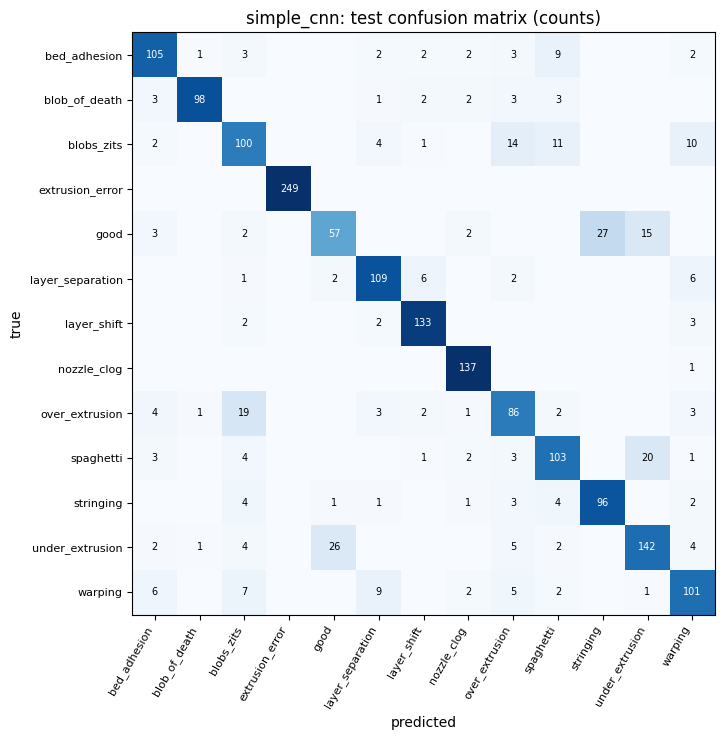

In [ ]:
RESULTS = {}

def get_model(name):
    if name in TRAINED:
        return TRAINED[name]['model']
    ck = torch.load(MODELS_DIR / f'{name}.pt', map_location='cpu')
    assert ck['classes'] == classes, 'saved model has different classes'
    m = build(name, n_classes); m.load_state_dict(ck['state_dict']); return m.to(device)

def evaluate(name):
    model = get_model(name)
    p, y, ids = predict(model, test_loader)
    pred = p.argmax(1)
    paths = [ds_test.samples[i][0] for i in ids]
    src = [Path(q).name.split('__')[0] for q in paths]
    df = pd.DataFrame(dict(file=[Path(q).name for q in paths], dataset=src,
                           true=[classes[i] for i in y], pred=[classes[i] for i in pred]))
    df['correct'] = df['true'] == df['pred']
    df.to_csv(RESULTS_DIR / f'{name}_test_predictions.csv', index=False)

    acc, f1 = accuracy_score(y, pred), f1_score(y, pred, average='macro')
    by_ds = df.groupby('dataset')['correct'].mean()
    RESULTS[name] = dict(model=name, test_accuracy=acc, test_macro_f1=f1,
                         **{f'acc_on_{d}': by_ds.get(d, np.nan) for d in DATASETS_PRESENT})
    print(f'===== {name} =====')
    print(f'test accuracy {acc:.3f}   macro-F1 {f1:.3f}')
    print('accuracy by dataset:', {k: round(v, 3) for k, v in by_ds.items()})
    print(classification_report(y, pred, labels=range(n_classes), target_names=classes, digits=3, zero_division=0))
    rec = df.groupby(['true', 'dataset'])['correct'].mean().unstack()
    print('recall per class and dataset (blank = class not in that dataset):')
    print(rec.round(3))

    cm = confusion_matrix(y, pred, labels=range(n_classes))
    cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1)
    fig, ax = plt.subplots(figsize=(8.5, 7.5))
    ax.imshow(cmn, cmap='Blues', vmin=0, vmax=1)
    ax.set_xticks(range(n_classes)); ax.set_xticklabels(classes, rotation=60, ha='right', fontsize=8)
    ax.set_yticks(range(n_classes)); ax.set_yticklabels(classes, fontsize=8)
    for i in range(n_classes):
        for j in range(n_classes):
            if cm[i, j]:
                ax.text(j, i, cm[i, j], ha='center', va='center', fontsize=7, color='white' if cmn[i, j] > 0.5 else 'black')
    ax.set_xlabel('predicted'); ax.set_ylabel('true'); ax.set_title(f'{name}: test confusion matrix (counts)')
    plt.tight_layout(); plt.savefig(RESULTS_DIR / f'{name}_confusion.png', dpi=130); plt.show()

evaluate('simple_cnn')

===== resnet50 =====
test accuracy 0.938   macro-F1 0.932
accuracy by dataset: {'bast': 0.992, 'd3d': 0.837, 'defcls': 0.957}
                  precision    recall  f1-score   support

    bed_adhesion      0.940     0.969     0.954       129
   blob_of_death      0.973     0.982     0.978       112
      blobs_zits      0.937     0.937     0.937       142
 extrusion_error      1.000     0.992     0.996       249
            good      0.780     0.670     0.721       106
layer_separation      0.984     0.976     0.980       126
     layer_shift      0.993     0.971     0.982       140
     nozzle_clog      0.993     1.000     0.996       138
  over_extrusion      0.883     0.934     0.908       121
       spaghetti      0.963     0.949     0.956       137
       stringing      0.844     0.964     0.900       112
 under_extrusion      0.874     0.860     0.867       186
         warping      0.946     0.925     0.935       133

        accuracy                          0.938      1831
  

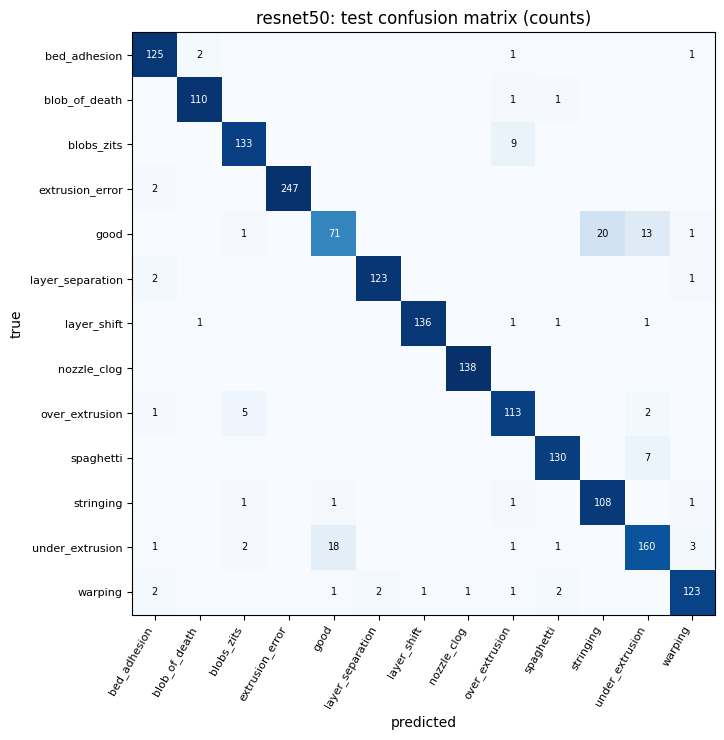

In [ ]:
evaluate('resnet50')

===== vit_small =====
test accuracy 0.915   macro-F1 0.905
accuracy by dataset: {'bast': 0.964, 'd3d': 0.756, 'defcls': 0.952}
                  precision    recall  f1-score   support

    bed_adhesion      0.905     0.961     0.932       129
   blob_of_death      0.973     0.982     0.978       112
      blobs_zits      0.918     0.951     0.934       142
 extrusion_error      1.000     0.964     0.982       249
            good      0.697     0.434     0.535       106
layer_separation      0.992     0.968     0.980       126
     layer_shift      0.993     0.971     0.982       140
     nozzle_clog      1.000     1.000     1.000       138
  over_extrusion      0.947     0.884     0.915       121
       spaghetti      0.969     0.920     0.944       137
       stringing      0.712     0.973     0.823       112
 under_extrusion      0.787     0.855     0.820       186
         warping      0.939     0.932     0.936       133

        accuracy                          0.915      1831
 

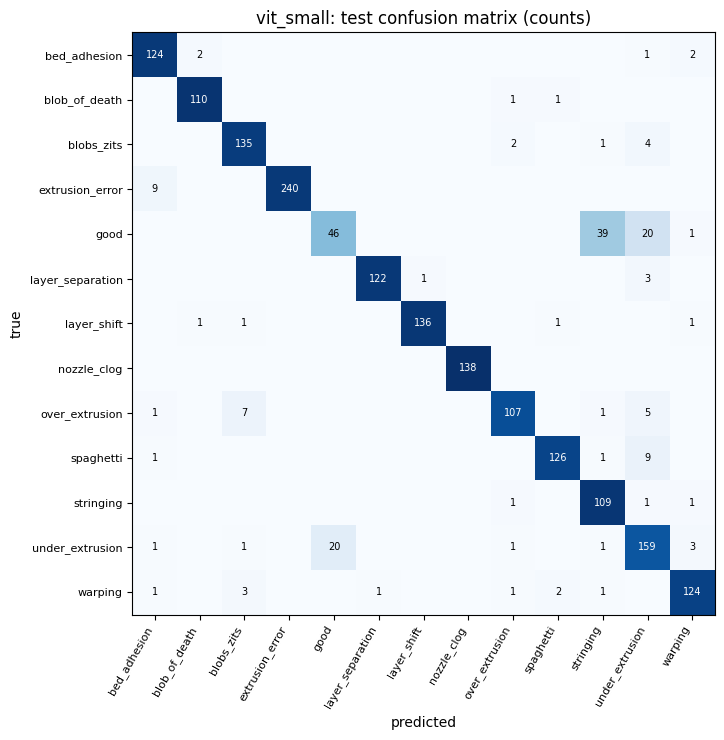

In [ ]:
evaluate('vit_small')

## Step 7: Compare the three models
One table and charts, saved to `results_improved/`. A 1-2 point difference is a tie. Compare this table with your first run's `summary.csv` to see what the changes did.

            test_accuracy  test_macro_f1  acc_on_bast  acc_on_d3d  \
model                                                               
simple_cnn          0.828          0.813        1.000       0.742   
resnet50            0.938          0.932        0.992       0.837   
vit_small           0.915          0.905        0.964       0.756   

            acc_on_defcls  params_M  best_epoch  train_minutes  
model                                                           
simple_cnn          0.818       1.0          21           54.2  
resnet50            0.957      23.5          10           27.7  
vit_small           0.952      21.7           5           20.3  


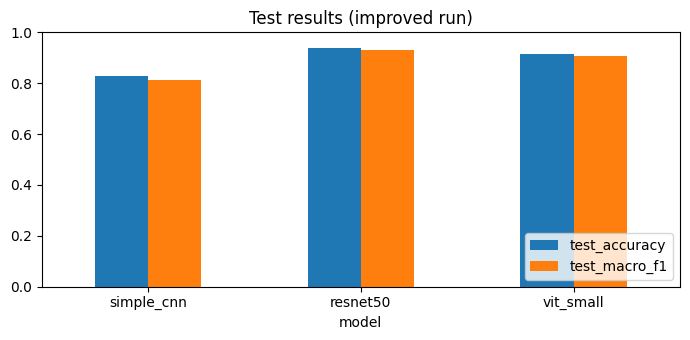

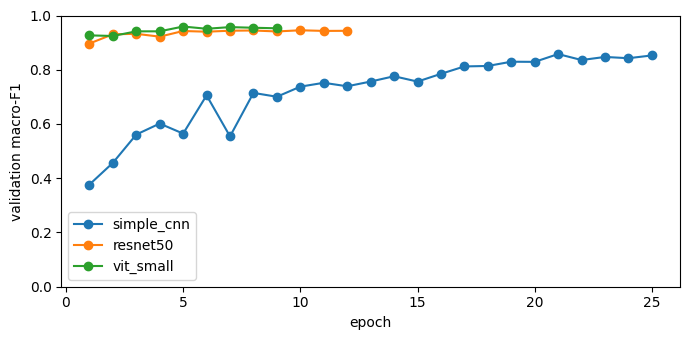

In [ ]:
rows = []
for name, r in RESULTS.items():
    t = TRAINED.get(name, {})
    rows.append({**r, 'params_M': round(t.get('params_m', np.nan), 1), 'best_epoch': t.get('best_ep', np.nan),
                 'train_minutes': round(t.get('secs', np.nan) / 60, 1)})
summary = pd.DataFrame(rows).set_index('model').round(3)
print(summary)
summary.to_csv(RESULTS_DIR / 'summary.csv')

fig, ax = plt.subplots(figsize=(7, 3.5))
summary[['test_accuracy', 'test_macro_f1']].plot.bar(ax=ax, rot=0)
ax.set_ylim(0, 1); ax.set_title('Test results (improved run)'); ax.legend(loc='lower right')
plt.tight_layout(); plt.savefig(RESULTS_DIR / 'comparison.png', dpi=130); plt.show()

if TRAINED:
    fig, ax = plt.subplots(figsize=(7, 3.5))
    for name, t in TRAINED.items():
        h = pd.DataFrame(t['hist'])
        ax.plot(h['epoch'], h['val_macro_f1'], marker='o', label=name)
    ax.set_xlabel('epoch'); ax.set_ylabel('validation macro-F1'); ax.legend(); ax.set_ylim(0, 1)
    plt.tight_layout(); plt.savefig(RESULTS_DIR / 'training_curves.png', dpi=130); plt.show()

## Step 8: Test on your own phone photos (optional)
Put each phone photo in `defect_project/phone_test/<its true defect>` and run this. These were never used for training. Expect lower scores (finished parts, different printer).

In [ ]:
PHONE = DRIVE / 'phone_test'
EXT = {'.jpg', '.jpeg', '.png', '.webp', '.bmp'}
items = []
for d in sorted(PHONE.glob('*')) if PHONE.exists() else []:
    if not d.is_dir(): continue
    imgs = [p for p in sorted(d.iterdir()) if p.suffix.lower() in EXT]
    if imgs and d.name not in classes:
        print(f'WARNING: folder {d.name!r} is not a model class, skipped.'); continue
    items += [(p, d.name) for p in imgs]

phone_rows = []
if not items:
    print('No phone photos found yet. Add some to', PHONE, 'and run this cell again.')
else:
    X = torch.stack([tf_eval(ImageOps.exif_transpose(Image.open(p)).convert('RGB')) for p, _ in items])
    true = [c for _, c in items]
    for name in ['simple_cnn', 'resnet50', 'vit_small']:
        try:
            model = get_model(name)
        except Exception:
            print(f'{name}: no trained model found, skipped'); continue
        model.eval(); probs = []
        with torch.no_grad():
            for k in range(0, len(X), BATCH):
                xb = X[k:k + BATCH].to(device)
                with torch.autocast(device_type=device, dtype=torch.float16, enabled=use_amp):
                    probs.append(model(xb).float().softmax(1).cpu())
        P = torch.cat(probs).numpy()
        top1 = [classes[i] for i in P.argmax(1)]
        top3 = [[classes[j] for j in np.argsort(-row)[:3]] for row in P]
        acc1 = np.mean([a == b for a, b in zip(top1, true)])
        acc3 = np.mean([t in tp for t, tp in zip(true, top3)])
        print(f'{name}: {len(items)} photos   top-1 {acc1:.3f}   top-3 {acc3:.3f}')
        for (p, t), a, tp in zip(items, top1, top3):
            phone_rows.append(dict(model=name, file=p.name, true=t, pred=a, top3=', '.join(tp), correct=(a == t)))
    pd.DataFrame(phone_rows).to_csv(RESULTS_DIR / 'phone_test_predictions.csv', index=False)
    print('saved phone_test_predictions.csv')

No phone photos found yet. Add some to /content/drive/MyDrive/defect_project/phone_test and run this cell again.
